# Vježba 3: *Zadatak za samostalan rad*


> Drazen Baric

In [1]:
import tensorflow as tf
import numpy as np
import matplotlib.pyplot as plt


A module that was compiled using NumPy 1.x cannot be run in
NumPy 2.2.6 as it may crash. To support both 1.x and 2.x
versions of NumPy, modules must be compiled with NumPy 2.0.
Some module may need to rebuild instead e.g. with 'pybind11>=2.12'.

If you are a user of the module, the easiest solution will be to
downgrade to 'numpy<2' or try to upgrade the affected module.
We expect that some modules will need time to support NumPy 2.

Traceback (most recent call last):  File "<frozen runpy>", line 198, in _run_module_as_main
  File "<frozen runpy>", line 88, in _run_code
  File "/Users/drazenbaric/Library/Python/3.12/lib/python/site-packages/ipykernel_launcher.py", line 18, in <module>
    app.launch_new_instance()
  File "/Users/drazenbaric/Library/Python/3.12/lib/python/site-packages/traitlets/config/application.py", line 1075, in launch_instance
    app.start()
  File "/Users/drazenbaric/Library/Python/3.12/lib/python/site-packages/ipykernel/kernelapp.py", line 739, in start
    self

AttributeError: _ARRAY_API not found

## Zadatci
<br>

1. Istrenirajte unaprijednu neuronsku mrežu s tri *skrivena* sloja za klasifikaciju slika iz **MNIST** skupa podataka koristeći koristeći `sparse_categorical_crossentropy` funkciju gubitka umjesto `categorical_crossentropy` funkcije gubitka.
> *Mreža na izlazu daje distribuciju vjerojatnosti po klasama.*

<br>

2. Prikažite **slučajan** uzorak od 18 **pogrešno klasificiranih** primjera iz skupa za testiranje zajedno s **distribucijom** (predviđenih) **vjerojatnosti** po klasama.

> Napraviti vizualizaciju po uzoru na onu iz *Vježbe 1*:
>
> <img alt="vizualizacija" src="https://drive.google.com/uc?id=1wfW_P1rdCdxn5KuWF953KIoy-uSjxFms" width=700px>



<br>

3. Usporedite prosječnu "sigurnost" modela u predviđanja pogrešno klasificiranih primjera i prosječnu "sigurnost" u predviđanja dobro klasificiranih primjera **iz skupa za testiranje**.

  - "*Sigurnost*": *vjerojatnost koju je neuronska mreža pridjelila klasi koju predviđa*




#### Rješenje 1.
> treniranje i evaluacija modela

In [2]:
(X_train, y_train), (X_test, y_test) = tf.keras.datasets.mnist.load_data()

In [3]:
X_train = X_train.astype('float32') / 255.0
X_test = X_test.astype('float32') / 255.0

In [4]:
model = tf.keras.Sequential([
    tf.keras.Input(shape=(28, 28)),
    tf.keras.layers.Flatten(),
    tf.keras.layers.Dense(64, activation='relu'),
    tf.keras.layers.Dense(64, activation='relu'),
    tf.keras.layers.Dense(64, activation='relu'),
    tf.keras.layers.Dense(10, activation='softmax')
])

In [5]:
model.compile(
    loss='sparse_categorical_crossentropy',
    optimizer='sgd',
    metrics=['accuracy']
)

In [6]:
povijest = model.fit(X_train, y_train, epochs=10, batch_size=32)

Epoch 1/10


   1/1875 ━━━━━━━━━━━━━━━━━━━━ 3:18 106ms/step - accuracy: 0.0000e+00 - loss: 2.3829

 132/1875 ━━━━━━━━━━━━━━━━━━━━ 0s 382us/step - accuracy: 0.1235 - loss: 2.2728      

 279/1875 ━━━━━━━━━━━━━━━━━━━━ 0s 361us/step - accuracy: 0.1952 - loss: 2.1710

 430/1875 ━━━━━━━━━━━━━━━━━━━━ 0s 351us/step - accuracy: 0.2716 - loss: 2.0433

...

1321/1875 ━━━━━━━━━━━━━━━━━━━━ 0s 342us/step - accuracy: 0.9702 - loss: 0.1012

1469/1875 ━━━━━━━━━━━━━━━━━━━━ 0s 342us/step - accuracy: 0.9703 - loss: 0.1010

1615/1875 ━━━━━━━━━━━━━━━━━━━━ 0s 342us/step - accuracy: 0.9704 - loss: 0.1008

1762/1875 ━━━━━━━━━━━━━━━━━━━━ 0s 342us/step - accuracy: 0.9704 - loss: 0.1006

1875/1875 ━━━━━━━━━━━━━━━━━━━━ 1s 344us/step - accuracy: 0.9710 - loss: 0.0986


In [7]:
test_loss, test_acc = model.evaluate(X_test, y_test)
print('Test loss: {:.4f}\nTest accuracy: {:.2f}%'.format(test_loss, test_acc*100))

  1/313 ━━━━━━━━━━━━━━━━━━━━ 13s 43ms/step - accuracy: 0.9688 - loss: 0.0891

180/313 ━━━━━━━━━━━━━━━━━━━━ 0s 280us/step - accuracy: 0.9554 - loss: 0.1426

313/313 ━━━━━━━━━━━━━━━━━━━━ 0s 288us/step - accuracy: 0.9654 - loss: 0.1118


Test loss: 0.1118
Test accuracy: 96.54%


#### Rješenje 2
> vizualizacija uzorka pogrešno razvrstanih primjera

  1/313 ━━━━━━━━━━━━━━━━━━━━ 4s 14ms/step

254/313 ━━━━━━━━━━━━━━━━━━━━ 0s 198us/step

313/313 ━━━━━━━━━━━━━━━━━━━━ 0s 247us/step


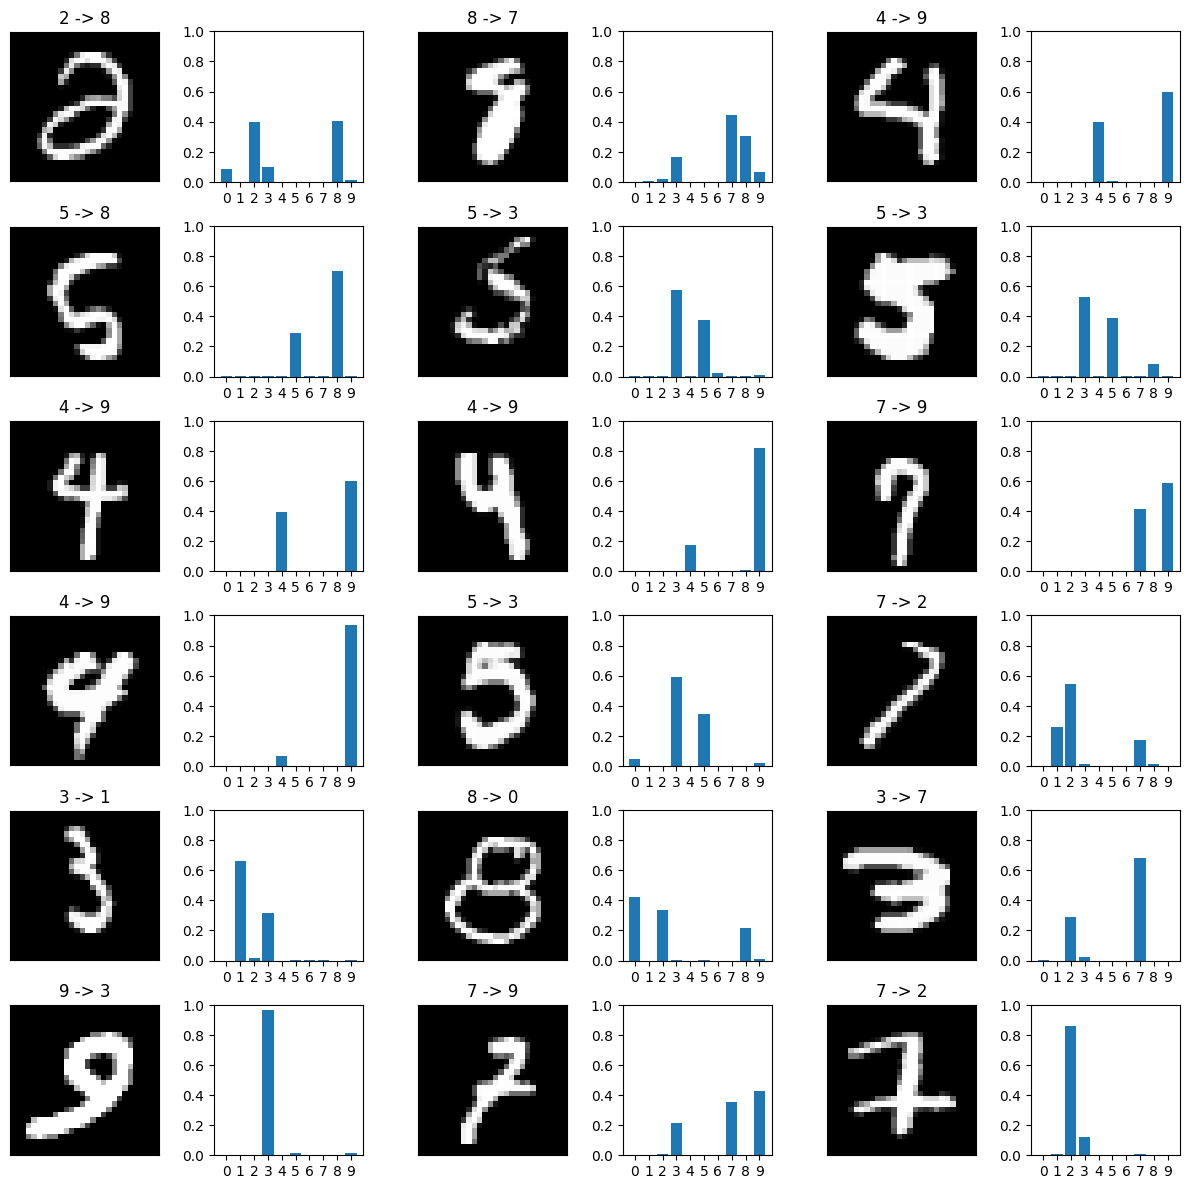

In [8]:
probs = model.predict(X_test)
pred = probs.argmax(axis=1)
wrong = np.where(pred != y_test)[0]
sample = np.random.choice(wrong, 18, replace=False)

fig = plt.figure(figsize=(12, 12))
for k, i in enumerate(sample):
    ax = fig.add_subplot(6, 6, 2*k + 1, xticks=[], yticks=[])
    ax.imshow(X_test[i], cmap='gray')
    ax.set_title(f'{y_test[i]} -> {pred[i]}')
    ax = fig.add_subplot(6, 6, 2*k + 2)
    ax.bar(range(10), probs[i])
    ax.set_xticks(range(10))
    ax.set_ylim(0, 1)
plt.tight_layout()
plt.show()

#### Rješenje 3
> "sigurnost" u dobro klasificirane primjere vs. "sigurnost" u pogrešno klasificirane primjere
>>

In [9]:
conf = probs.max(axis=1)
print(f'pogrešno klasificirani: {conf[pred != y_test].mean():.4f}')
print(f'dobro klasificirani: {conf[pred == y_test].mean():.4f}')

pogrešno klasificirani: 0.7096
dobro klasificirani: 0.9745
